# Josephson traveling-wave parametric amplifiers with JosephsonCircuits.jl

::::{admonition} Requirements
:class: tip

This notebook runs on a Julia 1.12 kernel. It solves the circuits with [JosephsonCircuits.jl](https://github.com/kpobrien/JosephsonCircuits.jl) and calls QPDK and matplotlib through [PythonCall.jl](https://github.com/JuliaPy/PythonCall.jl). From a source checkout, run `uv sync --extra models`. Then install the Julia environment and its kernel:

```sh
cd notebooks/data/josephsoncircuits_twpa/julia
julia --project=. -e 'using Pkg; Pkg.instantiate()'
julia --project=. -e 'using IJulia; installkernel("Julia", "--project=$(pwd())"; specname="julia-1.12")'
```

The first code cell points PythonCall at the checkout's `.venv` unless `JULIA_PYTHONCALL_EXE` is already set. See {ref}`notebook-extras`.
::::

A traveling-wave parametric amplifier (TWPA) uses a chain of Josephson junctions to amplify a weak signal. A strong pump changes the junction inductance. The signal at $f_\text{s}$ mixes with the pump at $f_\text{p}$ and creates an idler at $2f_\text{p}-f_\text{s}$ {cite:p}`macklinNearquantumlimitedJosephsonTravelingwave2015`.

Can resonators along the chain improve gain at the same incident pump power? We compare a uniform chain with a chain loaded by a resonator every fourth cell {cite:p}`obrienResonantPhaseMatching2014`. Blue means uniform and orange means loaded in every plot. Each circuit has its own pump solution.

Each junction follows the RCSJ equation {cite:p}`McCumber1968,tinkhamIntroductionSuperconductivity2015`:

$$I=I_\text{c}\sin\varphi+\frac{\Phi_0}{2\pi R}\dot\varphi+\frac{\Phi_0 C_\text{J}}{2\pi}\ddot\varphi.$$

The circuit follows the resonantly phase-matched JTWPA example distributed with JosephsonCircuits.jl {cite:p}`pengFloquetModeTravelingWaveParametric2022`. It has 2047 junctions. Each has $I_\text{c}=3.4\,\text{µA}$ and $C_\text{J}=55\,\text{fF}$. Ground capacitance is 45 fF per cell, halved at each end. A loaded cell replaces 30 fF of that capacitance with a 30 fF coupling capacitor to a 2.8153 pF / 170 pH parallel resonator at 7.275 GHz. The pump is 3.7 µA peak Norton current at 7.12 GHz, just below that resonance. Half that current is incident at the matched port. Its available power is $Z_0 I_\text{N}^2/8=85.56\,\text{pW}$, or -70.68 dBm {cite:p}`m.pozarMicrowaveEngineering2012`.

![Josephson ladder with ground capacitors and optional coupled LC resonators](figures/twpa-ladder.svg)

The {doc}`lumped JPA <vacask_lumped_parametric_amplifier>` and {doc}`CPW JPA <vacask_cpw_parametric_amplifier>` notebooks cover resonator amplifiers with VACASK.

In [1]:
import Pkg

const REPO = dirname(pwd())
Pkg.activate(joinpath(pwd(), "data", "josephsoncircuits_twpa", "julia"); io = devnull)
Pkg.instantiate(; io = devnull)

# Use the checkout's Python environment, which has QPDK, instead of a CondaPkg one.
get!(ENV, "JULIA_CONDAPKG_BACKEND", "Null")
get!(ENV, "JULIA_PYTHONCALL_EXE",
    joinpath(REPO, ".venv", Sys.iswindows() ? "Scripts\\python.exe" : "bin/python"))
get!(ENV, "MPLBACKEND", "Agg")

using JosephsonCircuits, PythonCall, Printf
include(joinpath(pwd(), "data", "josephsoncircuits_twpa", "julia", "twpa.jl"))
nothing

In [2]:
plt = pyimport("matplotlib.pyplot")
font_manager = pyimport("matplotlib.font_manager")
patches = pyimport("matplotlib.patches")
qpdk = pyimport("qpdk")
pyimport("qpdk.colormaps")  # registers the style colormap
qpdk.PDK.activate()
plt.style.use(joinpath(REPO, "docs", "qpdk.mplstyle"))

# The stylesheet names fonts that only the docs build ships.
fonts = get(ENV, "QPDK_DOCS_FONTS_DIR", joinpath(REPO, "build", "docs-fonts"))
if isdir(fonts)
    for font in readdir(fonts; join = true)
        endswith(font, ".otf") || endswith(font, ".ttf") || continue
        font_manager.fontManager.addfont(font)
    end
end

const COLORS = Dict(false => "C0", true => "C1")
const LABELS = Dict(false => "Uniform", true => "Phase matched")
const F_RESONATOR = 1 / (2pi * sqrt(170e-12 * 2.8153e-12))

"""Show a figure with Outfit titles, as the docs config does, then close it."""
function show_plot(fig)
    for ax in fig.axes
        ax.title.set_fontfamily("Outfit")
        ax.title.set_fontweight("bold")
    end
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    return nothing
end
nothing

## The circuit in JosephsonCircuits

JosephsonCircuits takes a netlist of `(name, node, node, value)` tuples. Names beginning with `L`, `C` and `R` are linear elements, `Lj` marks a Josephson junction given by its linear inductance $L_\text{J}=\Phi_0/(2\pi I_\text{c})$, and `P` declares a port. The helper `build_circuit` in `data/josephsoncircuits_twpa/julia/twpa.jl` writes the ladder; here are the first two cells of the loaded chain.

In [3]:
first(build_circuit(4, true), 17)

17-element Vector{Any}:
 ("P1", "n0", "0", 1)
 ("Rs", "n0", "0", 50.0)
 ("P2", "n4", "0", 2)
 ("Rl", "n4", "0", 50.0)
 ("Cg0", "n0", "0", 2.25e-14)
 ("Lj0", "n0", "n1", 9.679587529411765e-11)
 ("Cj0", "n0", "n1", 5.5e-14)
 ("Rj0", "n0", "n1", 1.0e9)
 ("Cg1", "n1", "0", 1.5e-14)
 ("Cc1", "n1", "r1", 3.0e-14)
 ("Cr1", "r1", "0", 2.8153e-12)
 ("Lr1", "r1", "0", 1.7e-10)
 ("Lj1", "n1", "n2", 9.679587529411765e-11)
 ("Cj1", "n1", "n2", 5.5e-14)
 ("Rj1", "n1", "n2", 1.0e9)
 ("Cg2", "n2", "0", 4.5e-14)
 ("Lj2", "n2", "n3", 9.679587529411765e-11)

## Cold dispersion

First set the pump to zero. `hblinsolve` without a pump solution is a linear AC analysis. We solve four cells, one loaded unit, between 50 Ω ports. The Bloch phase follows from the transfer-matrix trace {cite:p}`m.pozarMicrowaveEngineering2012`:

$$\cosh\gamma_4=\frac{A+D}{2}=\frac{1-S_{11}S_{22}+S_{12}S_{21}}{2S_{21}}.$$

Here $\operatorname{Re}\gamma_4$ is attenuation over four cells and $q=\operatorname{Im}\gamma_4/4$ is phase per junction. The plot hides the stopband where attenuation exceeds $10^{-3}$. The coupled resonators raise the pump wavenumber, which sits just below their resonance, and barely change the signal. Above the resonance, in the idler band, they lower it slightly. Both make the cold mismatch $2q_\text{p}-q_\text{s}-q_\text{i}$ positive.

The pump also shifts the wavenumbers through the junction nonlinearity. Expanding $I_\text{c}\sin\varphi$ to third order, a pump current of amplitude $I_\text{p}$ raises its own inductance by the factor $1+x/8$, with $x=(I_\text{p}/I_\text{c})^2$. It raises the inductance seen by the weak signal and idler by $1+x/4$. These are self- and cross-phase modulation. Since $q\propto\sqrt{L}$ for $q\ll1$, and $q_\text{s}+q_\text{i}\approx2q_\text{p}$, the total mismatch per junction is

```{math}
:label: eq:twpa-mismatch
\Delta q \simeq \left(2q_\text{p}-q_\text{s}-q_\text{i}\right)_\text{cold} - \frac{x}{8}\,q_\text{p}.
```

The Kerr term is negative, so a uniform chain is never phase matched under pump. The resonators supply a positive cold mismatch to cancel it {cite:p}`obrienResonantPhaseMatching2014`. The dashed lines show the cold mismatch that would give $\Delta q=0$. They assume the port is matched to the chain, so $I_\text{p}\approx I_\text{N}/2$. The estimate ignores pump depletion and the chain's 46 Ω impedance, so it explains trends rather than predicting gain.

Loading resonator at 7.275 GHz, (I_p/I_c)² = 0.296


Uniform: q_p = 0.0939 rad, cold mismatch at 5 GHz = -0.0003 rad; with Kerr shift at pump current 50%: -0.0012, 100%: -0.0038, 110%: -0.0045 rad


Phase matched: q_p = 0.0964 rad, cold mismatch at 5 GHz = +0.0049 rad; with Kerr shift at pump current 50%: +0.0040, 100%: +0.0013, 110%: +0.0006 rad


findfont: Failed to find font weight bold, now using 400.


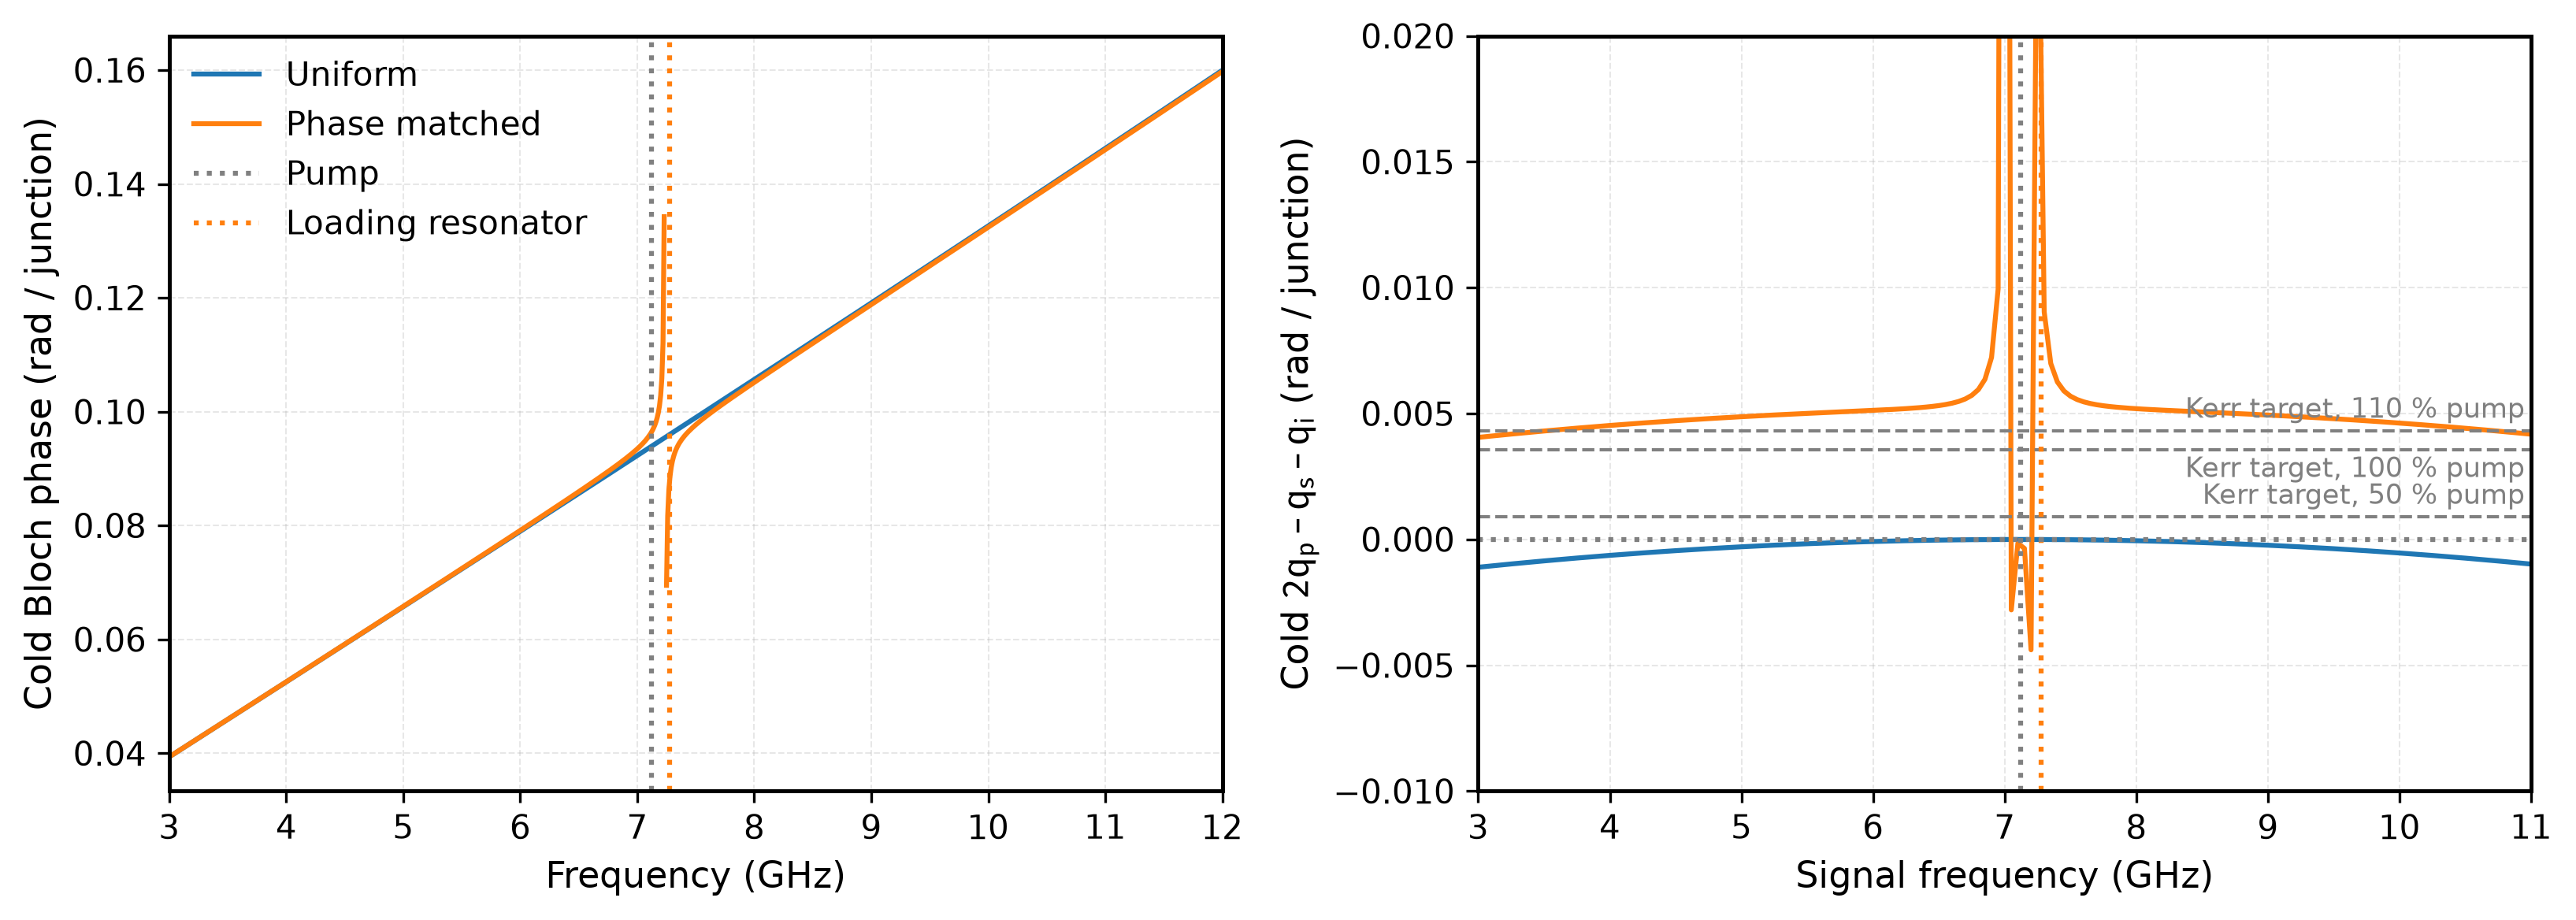

In [4]:
"""Complex Bloch exponent over one four-cell unit, from a linear JosephsonCircuits solve."""
function bloch_exponent(frequencies, matched)
    cold = hblinsolve(2pi .* frequencies, build_circuit(4, matched),
        Dict{Symbol, Float64}(); returnS = true, sorting = :name)
    s(output, input) = cold.S[1, output, 1, input, :]
    return acosh.((1 .- s(1, 1) .* s(2, 2) .+ s(1, 2) .* s(2, 1)) ./ (2 .* s(2, 1)))
end

bloch_phase(frequencies, matched) = imag.(bloch_exponent(frequencies, matched)) ./ 4

# The port is nearly matched to the chain, so about half the Norton current flows in.
const X_PUMP = (3.7e-6 / 2 / CRITICAL_CURRENT_A)^2
const PUMP_SHARES = (0.5, 1.0, 1.1)
const SIGNAL_HZ = collect(3e9:0.05e9:11e9)
const I5 = findfirst(==(5e9), SIGNAL_HZ)
@printf("Loading resonator at %.3f GHz, (I_p/I_c)² = %.3f\n", F_RESONATOR / 1e9, X_PUMP)

frequency = collect(range(3e9, 12e9; length = 901))
fig, (ax_bloch, ax_mismatch) = plt.subplots(1, 2; figsize = (11, 4))
q_p = Dict{Bool, Float64}()
for matched in (false, true)
    gamma = bloch_exponent(frequency, matched)
    ax_bloch.plot(frequency ./ 1e9, ifelse.(real.(gamma) .< 1e-3, imag.(gamma) ./ 4, NaN);
        color = COLORS[matched], label = LABELS[matched])
    q_p[matched] = only(bloch_phase([PUMP_FREQUENCY_HZ], matched))
    mismatch = 2q_p[matched] .- bloch_phase(SIGNAL_HZ, matched) .-
               bloch_phase(2PUMP_FREQUENCY_HZ .- SIGNAL_HZ, matched)
    ax_mismatch.plot(SIGNAL_HZ ./ 1e9, mismatch; color = COLORS[matched],
        label = LABELS[matched])
    totals = join(
        [@sprintf("%.0f%%: %+.4f", 100share,
             mismatch[I5] - q_p[matched] * share^2 * X_PUMP / 8)
         for share in PUMP_SHARES],
        ", ")
    @printf("%s: q_p = %.4f rad, cold mismatch at 5 GHz = %+.4f rad; with Kerr shift at pump current %s rad\n",
        LABELS[matched], q_p[matched], mismatch[I5], totals)
end
# Targets use the loaded chain's q_p; the uniform one is 3 % lower.
for share in PUMP_SHARES
    target = q_p[true] * share^2 * X_PUMP / 8
    ax_mismatch.axhline(target; color = "gray", ls = "--", lw = 1)
    # The 100 % label goes below its line so it clears the 110 % one.
    ax_mismatch.annotate("Kerr target, $(round(Int, 100share)) % pump",
        (SIGNAL_HZ[end] / 1e9, target); xytext = (-2, share == 1.0 ? -2 : 2),
        textcoords = "offset points", ha = "right", va = share == 1.0 ? "top" : "bottom",
        fontsize = "small", color = "gray")
end
for ax in (ax_bloch, ax_mismatch)
    ax.axvline(PUMP_FREQUENCY_HZ / 1e9; color = "gray", ls = ":", label = "Pump")
    ax.axvline(F_RESONATOR / 1e9; color = "C1", ls = ":", label = "Loading resonator")
end
ax_bloch.set(; xlabel = "Frequency (GHz)", ylabel = "Cold Bloch phase (rad / junction)")
ax_mismatch.axhline(0; color = "gray", ls = ":")
ax_mismatch.set(; xlabel = "Signal frequency (GHz)",
    ylabel = raw"Cold $2q_\text{p}-q_\text{s}-q_\text{i}$ (rad / junction)",
    ylim = (-0.01, 0.02))
ax_bloch.legend()
show_plot(fig)

At 5 GHz and full pump, Eq. {eq}`eq:twpa-mismatch` leaves the loaded chain at $+0.0013$ rad per junction and the uniform chain at $-0.0038$ rad. Over 2047 junctions the uniform chain accumulates about 8 rad of phase error, the loaded chain under 3 rad. Close to the pump both cold mismatches vanish and only the Kerr term is left, so the uniform chain amplifies best there.

The Kerr term grows with pump power while the cold mismatch does not, so the loading is tuned to one pump power {cite:p}`obrienResonantPhaseMatching2014`. At half the current the estimate reverses the order at 5 GHz: the uniform chain is then closer to phase matching ($-0.0012$ against $+0.0040$ rad per junction).

## Gain of the full chains

`hbsolve` first finds the periodic pump state with harmonic balance, then linearizes the circuit around it {cite:p}`pengFloquetModeTravelingWaveParametric2022`. The signal couples to every sideband $f_\text{s}+kf_\text{p}$ with even $k$. `solve_twpa` keeps the pump's odd harmonics through the 19th and sidebands through $|k|=10$, JosephsonCircuits' settings for this example. JosephsonCircuits normalizes its S-parameters to photon flux, so $|S_{k0}|^2$ is directly the number of photons that leave in sideband $k$ per incident signal photon. The idler at $2f_\text{p}-f_\text{s}$ is the negative-frequency sideband $k=-2$.

Solved both 2047-junction chains at 161 signal frequencies in 22 s
Uniform: G = 5.25 dB at 5 GHz, 12.04 dB peak


Phase matched: G = 25.00 dB at 5 GHz, 27.59 dB peak


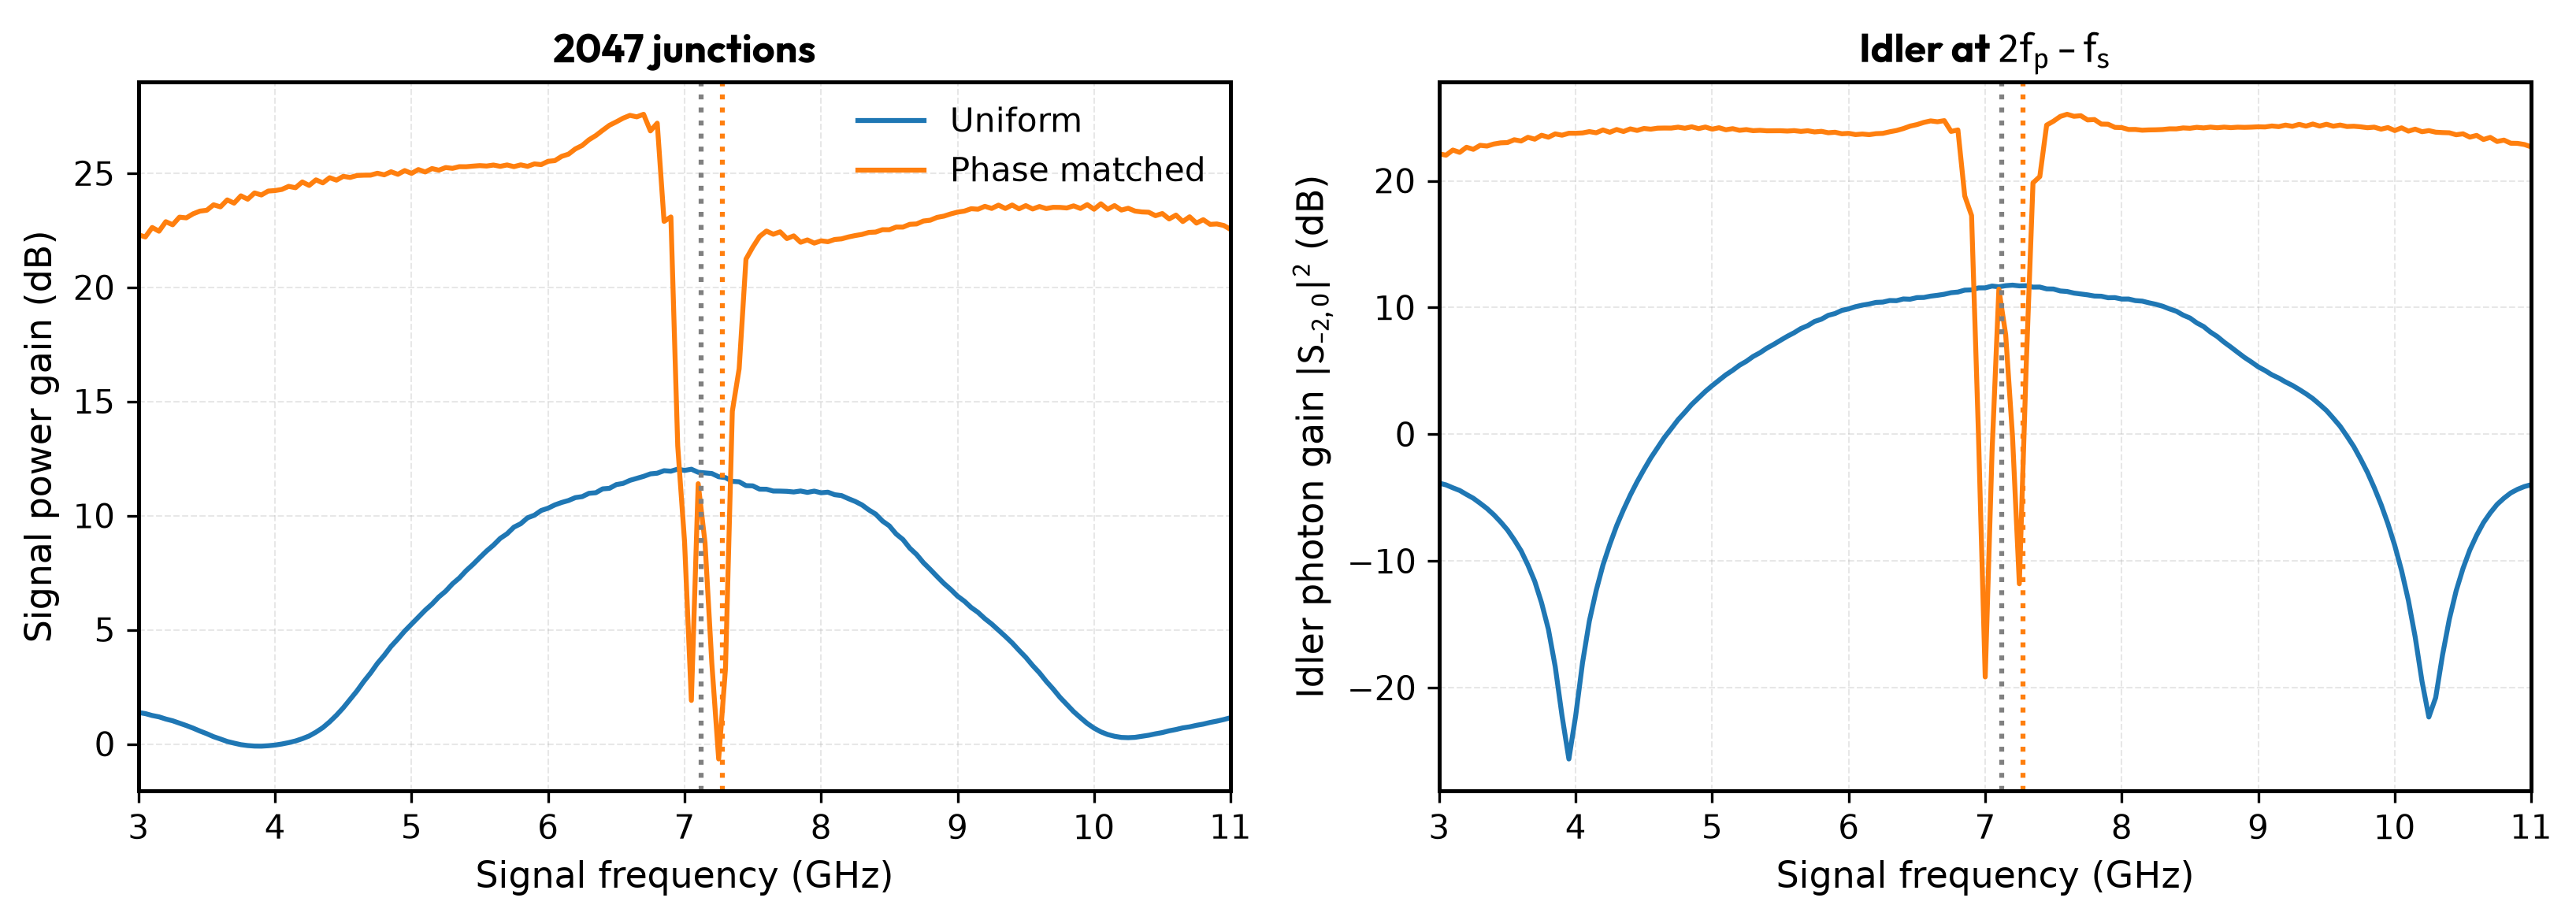

In [5]:
elapsed = @elapsed solutions = Dict(matched => solve_twpa(SIGNAL_HZ, 2047, matched)
for matched in (false, true))
@printf("Solved both 2047-junction chains at %d signal frequencies in %.0f s\n",
    length(SIGNAL_HZ), elapsed)

"""Photons leaving `port` in sideband `k` per signal photon incident on port 1."""
function photons(matched, k, port)
    [abs2(solutions[matched].linearized.S((k,), port, (0,), 1, n))
     for n in eachindex(SIGNAL_HZ)]
end

fig, (ax_gain, ax_idler) = plt.subplots(1, 2; figsize = (11, 4))
for matched in (false, true)
    gain = 10 .* log10.(photons(matched, 0, 2))
    @printf("%s: G = %.2f dB at 5 GHz, %.2f dB peak\n", LABELS[matched], gain[I5],
        maximum(gain))
    ax_gain.plot(SIGNAL_HZ ./ 1e9, gain; color = COLORS[matched], label = LABELS[matched])
    ax_idler.plot(SIGNAL_HZ ./ 1e9, 10 .* log10.(photons(matched, -2, 2));
        color = COLORS[matched], label = LABELS[matched])
end
for ax in (ax_gain, ax_idler)
    ax.axvline(PUMP_FREQUENCY_HZ / 1e9; color = "gray", ls = ":")
    ax.axvline(F_RESONATOR / 1e9; color = "C1", ls = ":")
end
ax_gain.set(; xlabel = "Signal frequency (GHz)", ylabel = "Signal power gain (dB)",
    title = "2047 junctions")
ax_idler.set(; xlabel = "Signal frequency (GHz)",
    ylabel = raw"Idler photon gain $|S_{-2,0}|^2$ (dB)",
    title = raw"Idler at $2f_\text{p}-f_\text{s}$")
ax_gain.legend()
show_plot(fig)

The resonators lift the gain from about 5 dB to 25 dB at 5 GHz, as the phase errors above suggest, and keep it above 20 dB on both sides of the pump. Signal and idler bands mirror each other around $f_\text{p}$. The loaded chain has a stopband at the resonator, between 7.0 and 7.3 GHz. The uniform chain peaks near the pump, where its cold mismatch vanishes.

## Where the signal photons go

Photons at negative-frequency sidebands enter the balance with a minus sign, because their creation operators mix with the signal's annihilation operator. For a lossless circuit, the Manley-Rowe relations then require {cite:p}`manleyGeneralPropertiesNonlinear1956,pengFloquetModeTravelingWaveParametric2022`

```{math}
:label: eq:twpa-photon-balance
\sum_{k}\sum_{\text{ports}}\operatorname{sign}(f_\text{s}+kf_\text{p})\,|S_{k0}|^2 = 1.
```

If the pump coupled the signal only to the idler, the $k=0$ and $k=-2$ terms alone would make up the sum. The bars show the terms at 5 GHz. Hatched bars are negative-frequency sidebands, which count with a minus sign.

Uniform: k = -2, f =  -9.24 GHz, 2.4 photons
Uniform: k = +0, f =   5.00 GHz, 3.4 photons


Uniform: two-mode balance -0.49 to 2.15, all sidebands 0.99999 to 1.00000
Phase matched: k = -6, f = -37.72 GHz, 2.0 photons


Phase matched: k = -4, f = -23.48 GHz, 81.4 photons
Phase matched: k = -2, f =  -9.24 GHz, 255.7 photons
Phase matched: k = +0, f =   5.00 GHz, 316.3 photons
Phase matched: k = +2, f =  19.24 GHz, 22.2 photons
Phase matched: k = +4, f =  33.48 GHz, 1.7 photons
Phase matched: two-mode balance -157.86 to 274.69, all sidebands 0.99989 to 1.00019


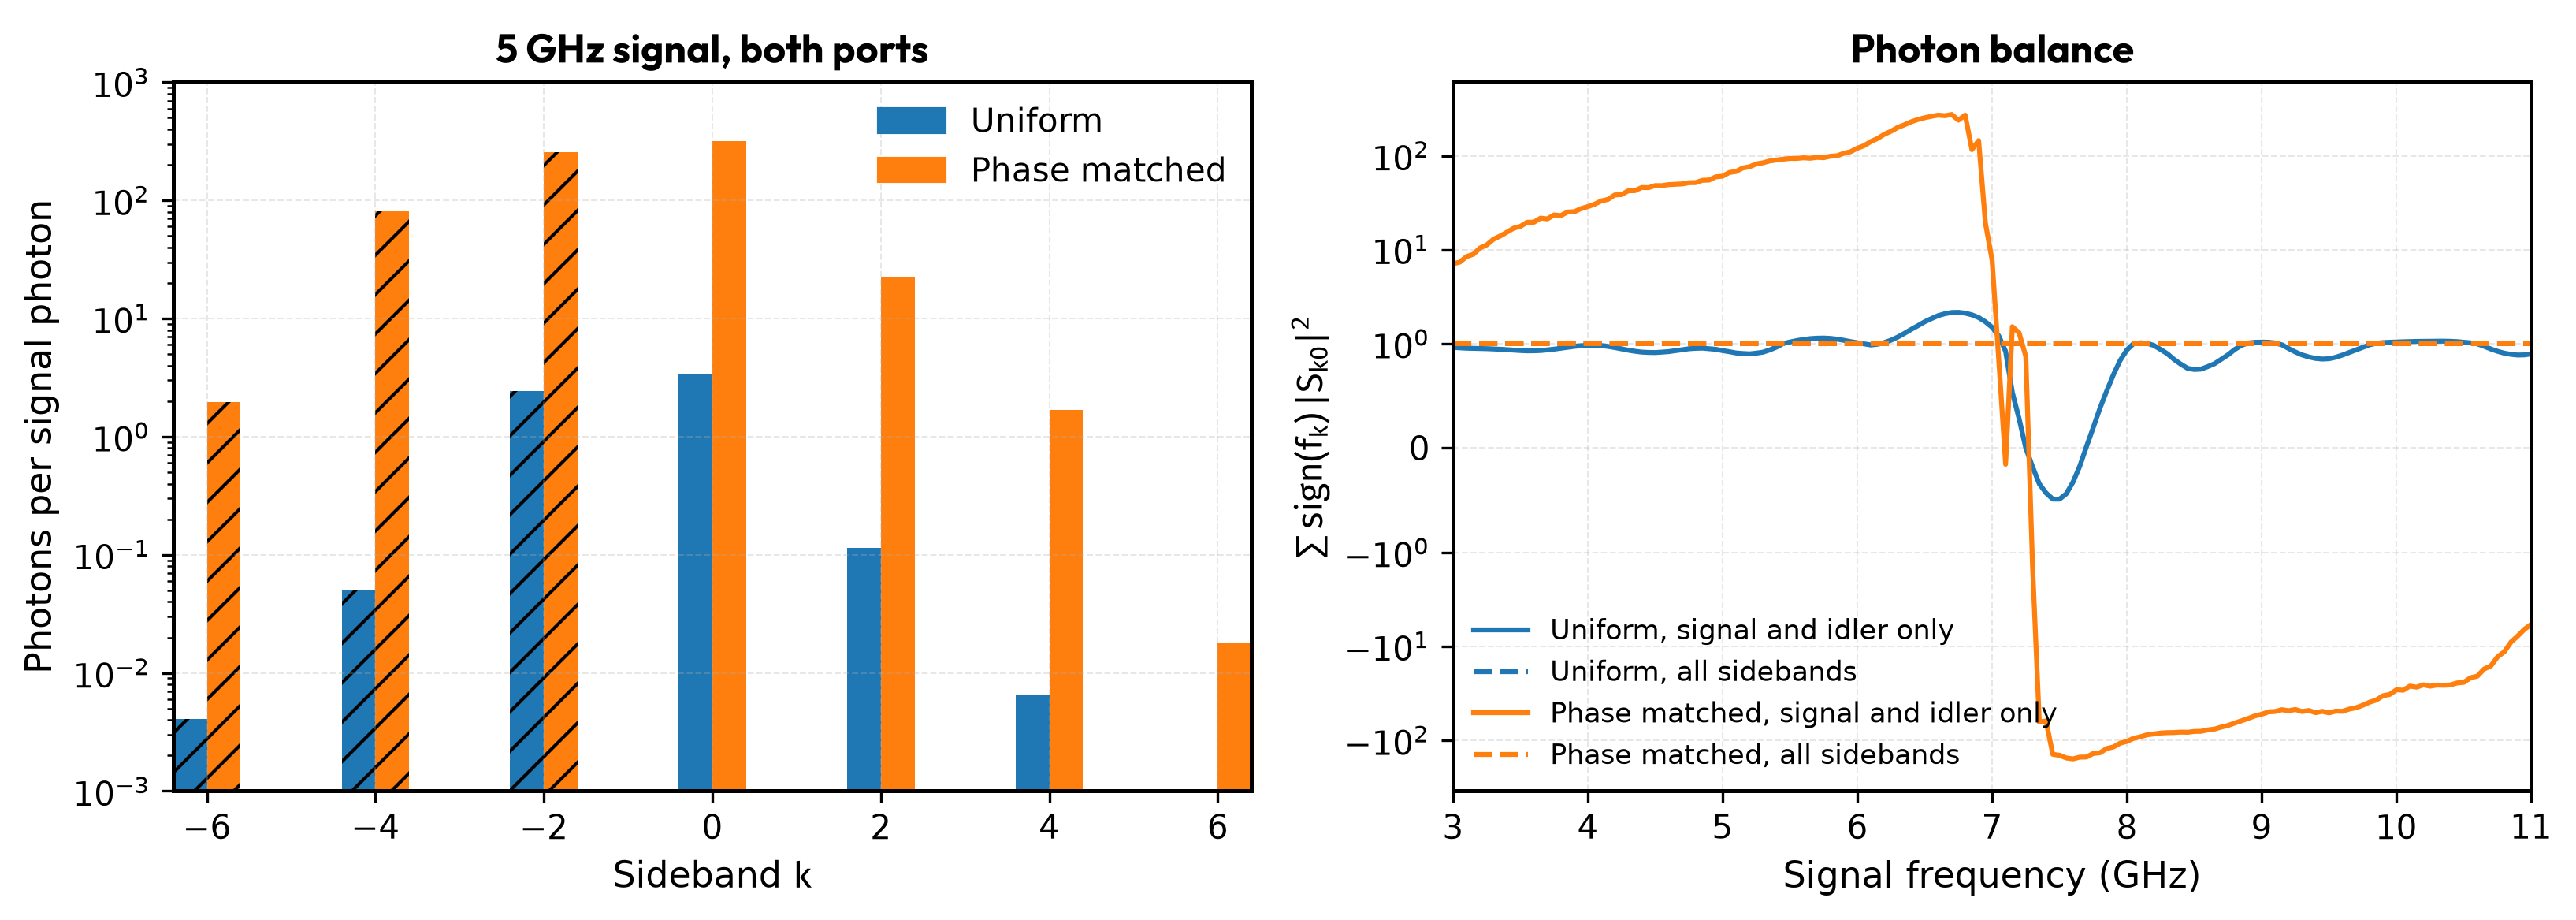

In [6]:
modes = [m[1] for m in solutions[true].linearized.modes]
fig, (ax_bars, ax_balance) = plt.subplots(1, 2; figsize = (11, 4))
for matched in (false, true)
    lin = solutions[matched].linearized
    sign_of(k) = sign(SIGNAL_HZ[I5] + k * PUMP_FREQUENCY_HZ)
    shown = [k for k in sort(modes) if abs(k) <= 6]
    total = [sum(abs2(lin.S((k,), port, (0,), 1, I5)) for port in 1:2) for k in shown]
    ax_bars.bar(shown .+ (matched ? 0.2 : -0.2), total; width = 0.4,
        color = COLORS[matched], label = LABELS[matched],
        hatch = [sign_of(k) < 0 ? "//" : "" for k in shown])
    for (k, n) in zip(shown, total)
        n > 1 && @printf("%s: k = %+d, f = %6.2f GHz, %.1f photons\n", LABELS[matched], k,
            (SIGNAL_HZ[I5] + k * PUMP_FREQUENCY_HZ) / 1e9, n)
    end

    two_mode = photons(matched, 0, 1) .+ photons(matched, 0, 2) .-
               photons(matched, -2, 1) .- photons(matched, -2, 2)
    full = [sum(sign(f + k * PUMP_FREQUENCY_HZ) * abs2(lin.S((k,), port, (0,), 1, n))
            for k in modes, port in 1:2)
            for (n, f) in enumerate(SIGNAL_HZ)]
    @printf("%s: two-mode balance %.2f to %.2f, all sidebands %.5f to %.5f\n",
        LABELS[matched], extrema(two_mode)..., extrema(full)...)
    ax_balance.plot(SIGNAL_HZ ./ 1e9, two_mode; color = COLORS[matched],
        label = "$(LABELS[matched]), signal and idler only")
    ax_balance.plot(SIGNAL_HZ ./ 1e9, full; color = COLORS[matched], ls = "--",
        label = "$(LABELS[matched]), all sidebands")
end
ax_bars.set(; yscale = "log", ylim = (1e-3, 1e3), xlabel = raw"Sideband $k$",
    ylabel = "Photons per signal photon", title = "5 GHz signal, both ports")
# Plain legend patches, since the first bar of each chain is hatched.
ax_bars.legend(;
    handles = [patches.Patch(; color = COLORS[m], label = LABELS[m]) for m in (false, true)])
ax_balance.set_yscale("symlog"; linthresh = 1)
ax_balance.set(; xlabel = "Signal frequency (GHz)",
    ylabel = raw"$\sum\,\operatorname{sign}(f_k)\,|S_{k0}|^2$",
    title = "Photon balance")
ax_balance.legend(; fontsize = "small")
show_plot(fig)

With all sidebands the balance stays within $2\times10^{-4}$ of 1 for both chains, so the circuit is lossless and the harmonic basis conserves photons. The symmetric-log axis shows the two-mode balance changing sign above the pump, where the other sidebands carry net positive-frequency photons. The signal and idler alone do not balance in the loaded chain. At 5 GHz it sends about 22 photons to $f_\text{s}+2f_\text{p}$ and 81 to $4f_\text{p}-f_\text{s}$. The uniform chain has the same sidebands, but with its low gain they carry only a fraction of a photon.

## Quantum efficiency

Each input mode carries half a photon of vacuum noise to the output {cite:p}`clerkIntroductionQuantumNoise2010`. JosephsonCircuits reports the quantum efficiency $\text{QE}=|S_{0,0}|^2/\sum_j |S_{0,j}|^2$: the share of the output noise at the signal frequency that came in with the signal. An ideal phase-preserving amplifier with power gain $G$ adds only the idler's vacuum, so $\text{QE}_\text{ideal}=G/(2G-1)$. The ratio $\eta=\text{QE}/\text{QE}_\text{ideal}$ is 1 at the quantum limit {cite:p}`pengFloquetModeTravelingWaveParametric2022`. Every extra sideband that feeds the signal output lowers it.

Uniform: η = 0.913 at 5 GHz
Phase matched: η = 0.908 at 5 GHz


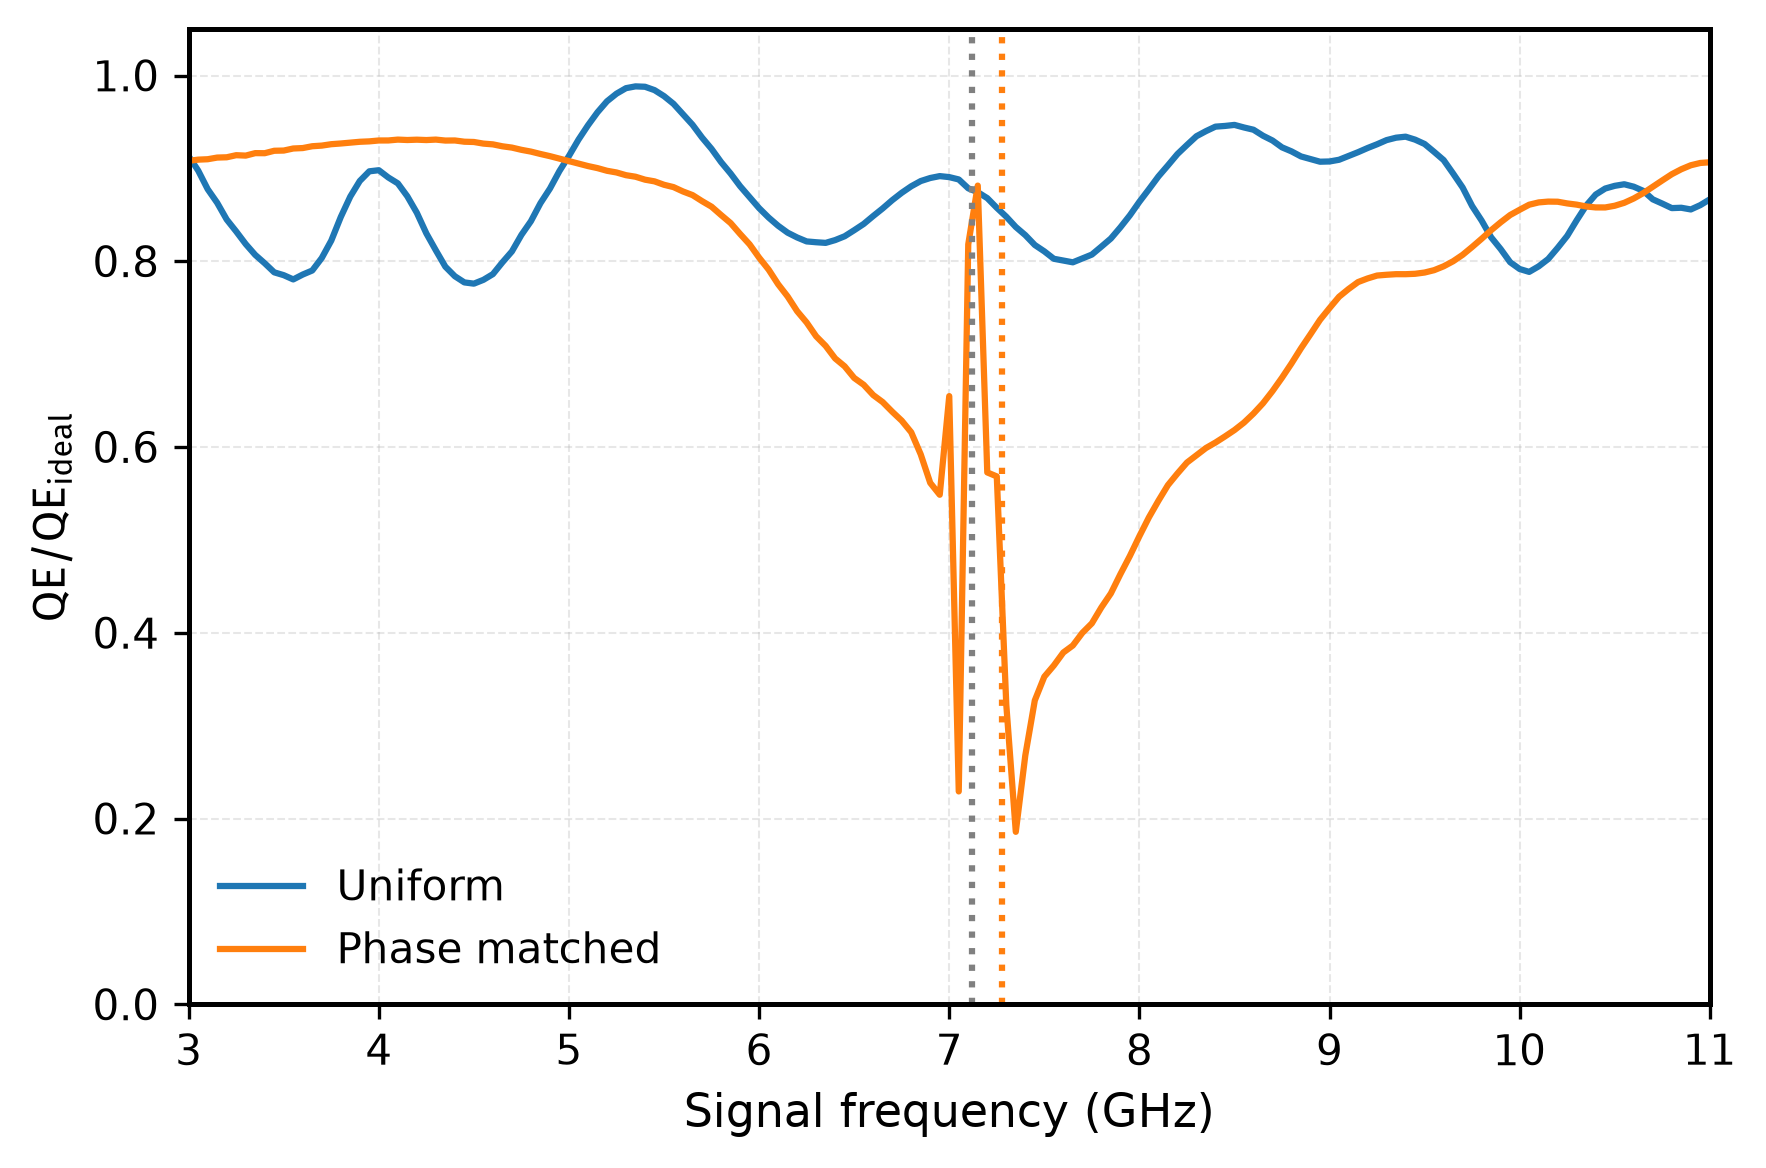

In [7]:
eta(lin, n) = lin.QE((0,), 2, (0,), 1, n) / lin.QEideal((0,), 2, (0,), 1, n)
qe_ratio(matched) = [eta(solutions[matched].linearized, n) for n in eachindex(SIGNAL_HZ)]

fig, ax = plt.subplots(; figsize = (6, 4))
for matched in (false, true)
    efficiency = qe_ratio(matched)
    @printf("%s: η = %.3f at 5 GHz\n", LABELS[matched], efficiency[I5])
    ax.plot(SIGNAL_HZ ./ 1e9, efficiency; color = COLORS[matched], label = LABELS[matched])
end
ax.axvline(PUMP_FREQUENCY_HZ / 1e9; color = "gray", ls = ":")
ax.axvline(F_RESONATOR / 1e9; color = "C1", ls = ":")
ax.set(;
    xlabel = "Signal frequency (GHz)", ylabel = raw"$\text{QE}/\text{QE}_\text{ideal}$",
    ylim = (0, 1.05))
ax.legend()
show_plot(fig)

Below the pump the loaded chain keeps $\eta$ near 0.9 up to 5.5 GHz, then loses efficiency toward the resonator. Just above the stopband, at 7.5 GHz, $\eta$ is 0.35 although the gain is still about 22 dB. The uniform chain stays between 0.78 and 0.99. Gain alone does not qualify a TWPA as a quantum-limited amplifier. {cite:t}`pengFloquetModeTravelingWaveParametric2022` show how a Floquet-mode design suppresses these sidebands and recovers $\eta$.

## Harmonic basis

The harmonic basis is a numerical truncation. Doubling both the pump harmonics and the sidebands checks it on a coarser grid.

In [8]:
coarse = collect(3e9:0.25e9:11e9)
for matched in (false, true)
    base, fine = (solve_twpa(coarse, 2047, matched; pump_harmonics = h,
                      modulation_harmonics = k).linearized
    for (h, k) in ((20, 10), (40, 20)))
    gain_error = maximum(abs(10log10(abs2(fine.S((0,), 2, (0,), 1, n)) /
                                     abs2(base.S((0,), 2, (0,), 1, n))))
    for n in eachindex(coarse))
    eta_error = maximum(abs(eta(fine, n) - eta(base, n)) for n in eachindex(coarse))
    @printf("%s: doubling the basis changes G by at most %.1e dB and η by %.1e\n",
        LABELS[matched], gain_error, eta_error)
end

Uniform: doubling the basis changes G by at most 1.8e-03 dB and η by 4.3e-05


Phase matched: doubling the basis changes G by at most 8.9e-03 dB and η by 3.1e-04


Both chains are converged in the basis to far better than the plots resolve.

## From QPDK layout to circuit values

PythonCall gives Julia the whole QPDK Python API. Below is the {func}`~qpdk.cells.junction.josephson_junction` cell, built and plotted from Julia.

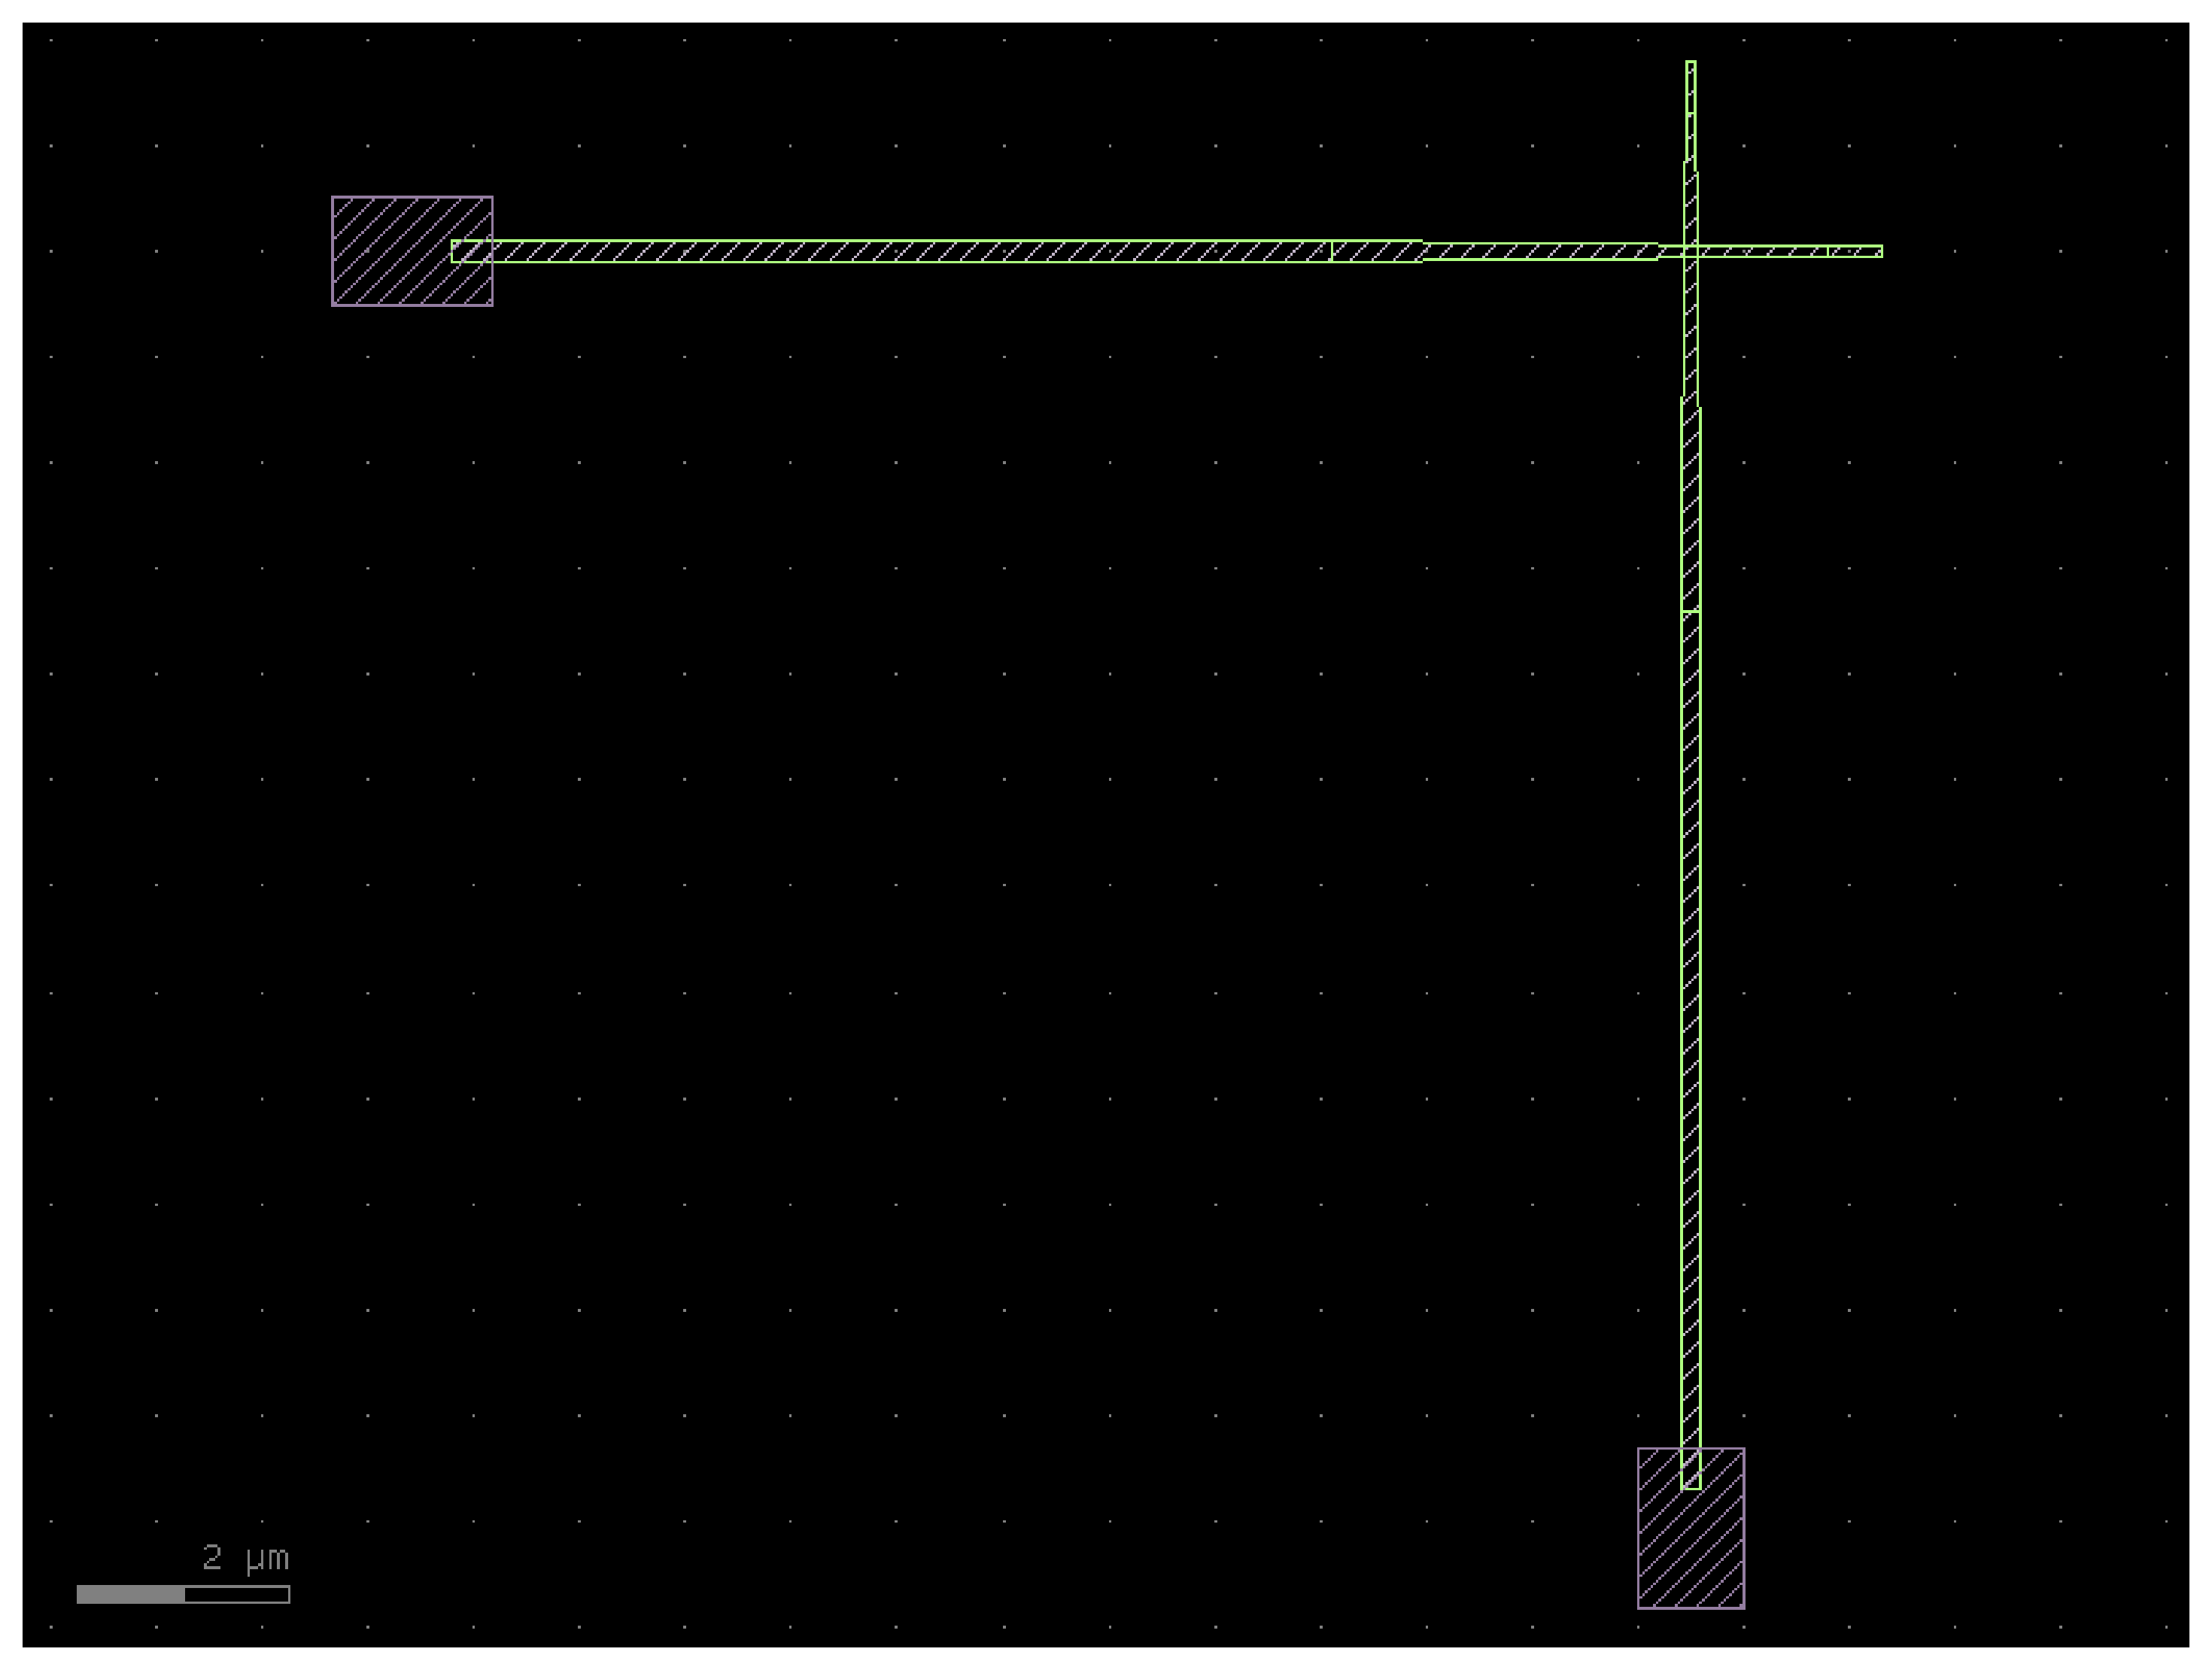

In [9]:
junction = qpdk.cells.josephson_junction()
junction.plot()
show_plot(plt.gcf())

Its overlap is the square of the narrow wire width. The Ambegaokar-Baratoff relation $I_\text{c}R_\text{n}=\pi\Delta/2e$ gives the normal-state resistance that room-temperature probing must hit for a target $I_\text{c}$ {cite:p}`ambegaokarTunnelingSuperconductors1963`. We take the aluminium gap $\Delta\approx180\,\text{µeV}$ {cite:p}`tinkhamIntroductionSuperconductivity2015`.

In [10]:
width_um = pyconvert(Float64, qpdk.tech.josephson_junction_cross_section_narrow().width)
area_um2 = width_um^2
gap_ev = 180e-6
@printf("Default overlap %.3f µm × %.3f µm = %.4f µm²\n", width_um, width_um, area_um2)
@printf("For I_c = %.1f µA: J_c = %.0f µA/µm², R_n = %.0f Ω\n", CRITICAL_CURRENT_A * 1e6,
    CRITICAL_CURRENT_A * 1e6 / area_um2, pi * gap_ev / (2 * CRITICAL_CURRENT_A))

Default overlap 0.090 µm × 0.090 µm = 0.0081 µm²
For I_c = 3.4 µA: J_c = 420 µA/µm², R_n = 83 Ω


The default cell is sized for a transmon, so its overlap would need an unrealistic critical-current density. At a few µA/µm², a 3.4 µA TWPA junction needs an overlap of about 1 µm², over a hundred times larger. A TWPA layout will replace these circuit targets with values extracted from the drawn cells:

| Circuit part | QPDK layout starting point | Values still needed |
| --- | --- | --- |
| Junction | {func}`~qpdk.cells.junction.josephson_junction` | Process-calibrated $I_\text{c}$, $C_\text{J}$ and shunt resistance. |
| Ground and coupling capacitors | {func}`~qpdk.cells.capacitor.interdigital_capacitor` | A capacitance extraction including nearby ground and pads. |
| Loading resonator | {func}`~qpdk.cells.inductor.meander_inductor` and capacitor cells | Inductance including kinetic inductance, capacitance and parasitic coupling. |

The {doc}`capacitor extraction <elmer_capacitance_interdigital>` and {doc}`CPW field simulation <comsol_cpw_resonator>` notebooks show extraction routes. The {doc}`CPW JPA notebook <vacask_cpw_parametric_amplifier>` shows the full route for a resonator amplifier: one QPDK cross-section and the measured layout length feed both SAX and VACASK.

## Limits of these results

These are small-signal results around a stable classical pump. They do not establish pump stability, gain compression or squeezing {cite:p}`clerkIntroductionQuantumNoise2010,royIntroductionParametricAmplification2016`. The quantum efficiency counts vacuum noise from the ports only; the 1 GΩ junction shunt is nearly lossless, so dielectric and quasiparticle loss would lower $\eta$ further. The RCSJ model also omits higher Josephson harmonics seen in real junctions {cite:p}`willschObservationJosephsonHarmonics2024`. The phase-mismatch estimate ignores pump depletion. None of this establishes agreement with a fabricated device.

## References

```{bibliography}
:filter: docname in docnames
```